# Part 1

# Preparation

- import libraries
- load data

In [2]:
import pandas as pd
from data_profiling import ProfileReport

In [3]:
import duckdb

%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.displaycon = False
%config SqlMagic.feedback = 0

conn = duckdb.connect("../deel_test.duckdb", read_only=True, config={"TimeZone": "UTC"})
%sql conn

The 'toml' package isn't installed. To load settings from pyproject.toml or ~/.jupysql/config, install with: pip install toml

In [4]:
# DataFrames for profiling, loaded from the raw DuckDB tables
acceptance = conn.sql("SELECT * FROM globepay.raw_acceptance_report").df()
chargeback = conn.sql("SELECT * FROM globepay.raw_chargeback_report").df()

# Data Profiling

## Notable findings:
Following statements are true for the data sample and might not be true for the whole data source as this sample.

- 'status' is always true
- 'source' is globalpay only which is expected
- Data is in period from 2019-01-01 to 2019-06-30
- 'amount' has negative values
- 'amount' is not in minor units since it has decimal points
- 'country' has UK which is not ISO alpha 2 code for United Kingdom (it should be GB)
- 'cvv_provided' is highly imbalanced (only 40 True records which is 0.7% of records)

In [5]:
ProfileReport(acceptance, title="Acceptance Report DataFrame").to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 11/11 [00:00<00:00, 1440.94it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [6]:
ProfileReport(chargeback, title="Chargback Report DataFrame").to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 4/4 [00:00<00:00, 276.95it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

# Exploration

### There are 2x times more USD transactions than other transactions according to profiling. AE (United Arab Emirates) have USD transactions assigned to them. Official currency should be AED (United Arab Emirates dirham)


AED is pegged to US dollar. We can use exchange rate of 1 USD = 3.6725 AED

In [6]:
%%sql
SELECT country, currency, COUNT(1) FROM globepay.raw_acceptance_report
GROUP BY country, currency

,country,currency,count(1)
0,FR,EUR,905
1,MX,MXN,905
2,UK,GBP,905
3,CA,CAD,905
4,US,USD,905
5,AE,USD,905


### UK (GBP) have negative amount record and different distribution in first quartiles as opposed to other transactions

In [7]:
%%sql
SELECT country,
       currency,
       COUNT(*) AS n,
       MIN(amount) AS min,
       ROUND(QUANTILE_CONT(amount, 0.01), 2) AS p01,
       ROUND(QUANTILE_CONT(amount, 0.05), 2) AS p05,
       ROUND(QUANTILE_CONT(amount, 0.10), 2) AS p10,
       ROUND(QUANTILE_CONT(amount, 0.25), 2) AS p25,
       ROUND(MEDIAN(amount), 2) AS median,
       ROUND(AVG(amount), 2) AS mean,
       ROUND(QUANTILE_CONT(amount, 0.99), 2) AS p99,
       MAX(amount) AS max,
       COUNT_IF(amount < 0) AS negative,
       COUNT_IF(amount = 0) AS zero
FROM globepay.raw_acceptance_report
GROUP BY country, currency
ORDER BY country, currency


,country,currency,n,min,p01,p05,p10,p25,median,mean,p99,max,negative,zero
0,AE,USD,905,1007.43,3215.25,8547.30,18910.50,48114.50,96553.35,91618.38,177813.42,180371.52,0.0,0.0
1,CA,CAD,905,619.31,3380.56,9653.17,16640.38,37542.74,88445.91,88268.49,175360.87,176270.30,0.0,0.0
2,FR,EUR,905,1666.21,3270.99,12491.37,20904.98,43842.83,88543.18,88534.45,176240.46,178568.77,0.0,0.0
3,MX,MXN,905,1509.12,3204.46,10267.73,16008.63,48894.70,88415.69,85614.71,163234.85,166162.81,0.0,0.0
4,UK,GBP,905,-23.78,459.95,6690.44,16973.97,41391.37,79586.57,81141.00,165946.59,168365.96,1.0,0.0
5,US,USD,905,1020.46,3679.01,10995.86,19197.15,40253.70,82128.16,86454.61,176257.02,177874.73,0.0,0.0


In [8]:
%%sql
SELECT
    a.*,
    c.status AS chargeback_status,
    c.source AS chargeback_source,
    c.chargeback
FROM globepay.raw_acceptance_report AS a
LEFT JOIN globepay.raw_chargeback_report AS c
    ON a.external_ref = c.external_ref
WHERE a.amount < 0


,external_ref,status,source,ref,date_time,state,cvv_provided,amount,country,currency,rates,chargeback_status,chargeback_source,chargeback
0,SPm_aqm_Rrer_6jxpLvO2,True,GLOBALPAY,evt_1EhCNv4mRDFQzT2r2O5Cy5G,2019-01-01 04:48:00+00:00,ACCEPTED,False,-23.78,UK,GBP,"{""CAD"":1.4173511828553305,""EUR"":0.922579749754...",True,GLOBALPAY,True


### CVV provided imbalance

In [9]:
%%sql
SELECT cvv_provided, COUNT(1) FROM globepay.raw_acceptance_report
GROUP BY cvv_provided

,cvv_provided,count(1)
0,False,5390
1,True,40


### identifier matching between tables check

In [10]:
%%sql
SELECT COUNT(*) AS total,
       COUNT_IF(a.external_ref IS NOT NULL AND c.external_ref IS NOT NULL) AS matched,
       COUNT_IF(c.external_ref IS NULL) AS acceptance_only,
       COUNT_IF(a.external_ref IS NULL) AS chargeback_only
FROM globepay.raw_acceptance_report a
FULL OUTER JOIN globepay.raw_chargeback_report c USING (external_ref)

,total,matched,acceptance_only,chargeback_only
0,5430,5430.0,0.0,0.0


### Always the same currencies in 'rates' field
And we have no AED (mentioned above as a problem)

In [11]:
%%sql
SELECT json_keys(rates) AS currencies,
       COUNT(*) AS n,
       COUNT(DISTINCT rates) AS distinct_rate_sets
FROM globepay.raw_acceptance_report
GROUP BY 1
ORDER BY n DESC

,currencies,n,distinct_rate_sets
0,"[CAD, EUR, MXN, USD, SGD, AUD, GBP]",5430,1086


# Summary of the model architecture

Raw data is ingested via python script into DWH (duckdb). Raw tables globepay.raw_acceptance_report and globepay.raw_chargeback_report are defined as sources. On top of them 2 staging models are built and materialized as views to clean data, fix errors and normalize naming where applicable. There's no need for intermediate tables in this scenario. Downstream the 'payments' mart is built by joining staging views of acceptance report and chargeback report. 'payments' are materialized as table. We cannot use transaction timestamp for incremental updates of the table because chargeback data could arrive much later in the process and for that we need some sort of timestamp to monitor last updated at timestamp of chargebacks. Chargebacks are left joined to Acceptance because a transaction might be missing from the chargeback report (although this is not the case for the sample). The goal is to still have all card transactions without chargeback information.


Main assumptions:
- AED is wrongly labeled as USD for AE (it could be USD actually for AE)
- Negative amount record in source data is really just a sign error and could be fixed with ABS()

# Lineage Graph

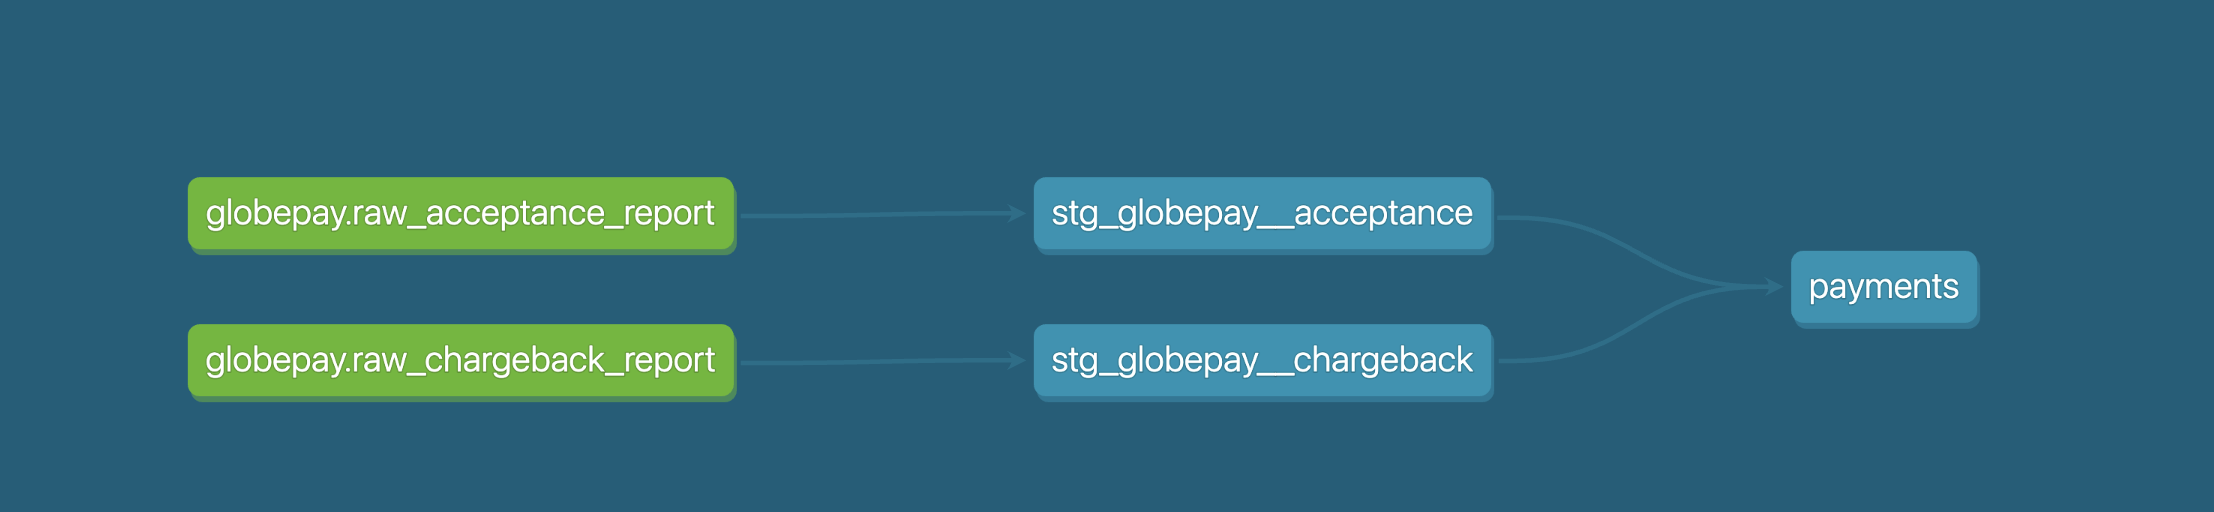

# Macros, Data Validation, Documentation Tips

- Add seed country codes and currency codes and use them in tests for staging to check for unusual values
- keep track of your own official fx rate and compare how it differce from payment provider
- add source freshness checks
- {% docs %} blocks to reuse documentation where applicable
- Add semantic layer to document common measures and metrics so that downstream consumers could use them instead of defining their own
- Add meta tags to models to document owners, PII
- Create a macros to convert_to_usd(amount, currency, rates) if new data sources have the same problem to reuse the code

# Part 2

## 1. What is the acceptance rate over time?
- Stays at around 68-72% for the time period provided. April 2019 was the lowest month with 68% acceptance rate and June 2019 was the highest month with 72%

In [12]:
%%sql acceptance_by_month <<
SELECT
    CAST(DATE_TRUNC('month', transaction_date) AS DATE) AS transaction_month,
    COUNT(*) AS transactions,
    COUNT_IF(is_accepted) AS accepted_transactions,
    ROUND(COUNT_IF(is_accepted) / COUNT(*), 2) AS acceptance_rate
FROM payments
GROUP BY transaction_month
ORDER BY transaction_month


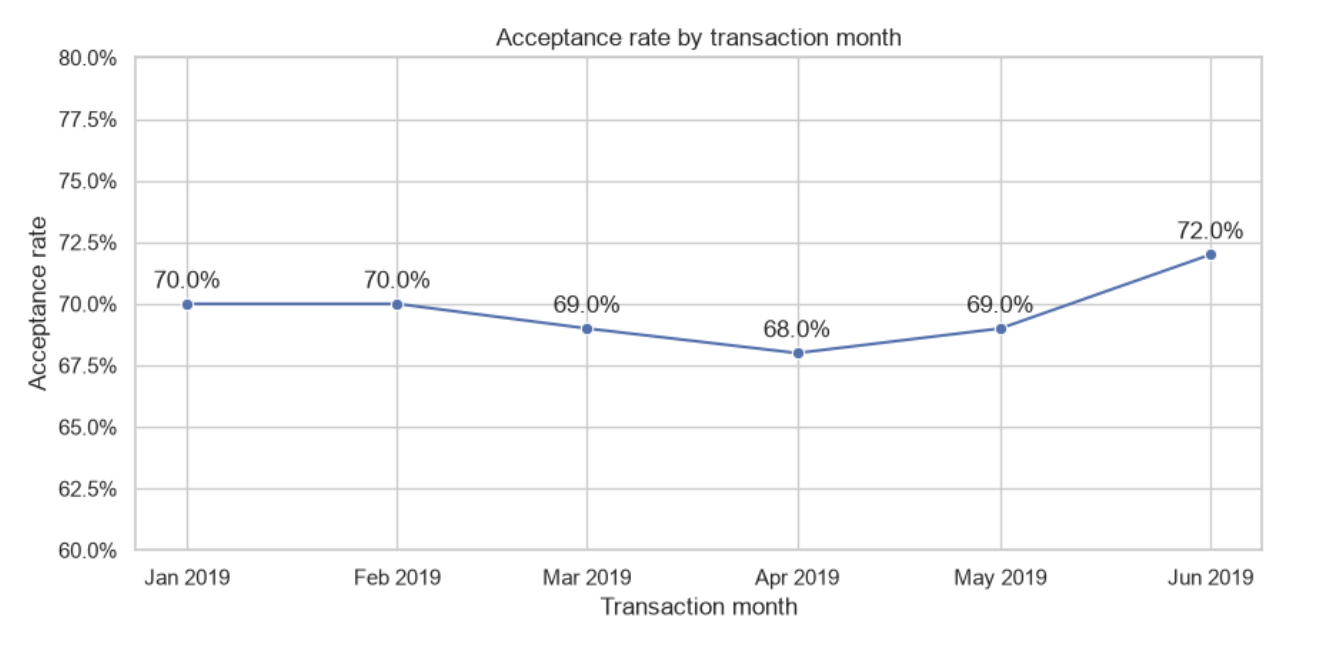

## 2. List the countries where the amount of declined transactions went over $25M

3 countries: France, United Kingdom, United States. United States is barely over threshold of $25 million. The data is aggregated for the whole period of January 2019 - June 2019

In [13]:
%%sql
SELECT
    country,
    COUNT(*) AS declined_transactions,
    SUM(amount_usd) AS declined_amount_usd
FROM payments
WHERE is_accepted IS FALSE
GROUP BY country
HAVING SUM(amount_usd) > 25000000
ORDER BY declined_amount_usd DESC


,country,declined_transactions,declined_amount_usd
0,FR,271,32628786.68
1,GB,258,27489495.64
2,US,297,25125669.78


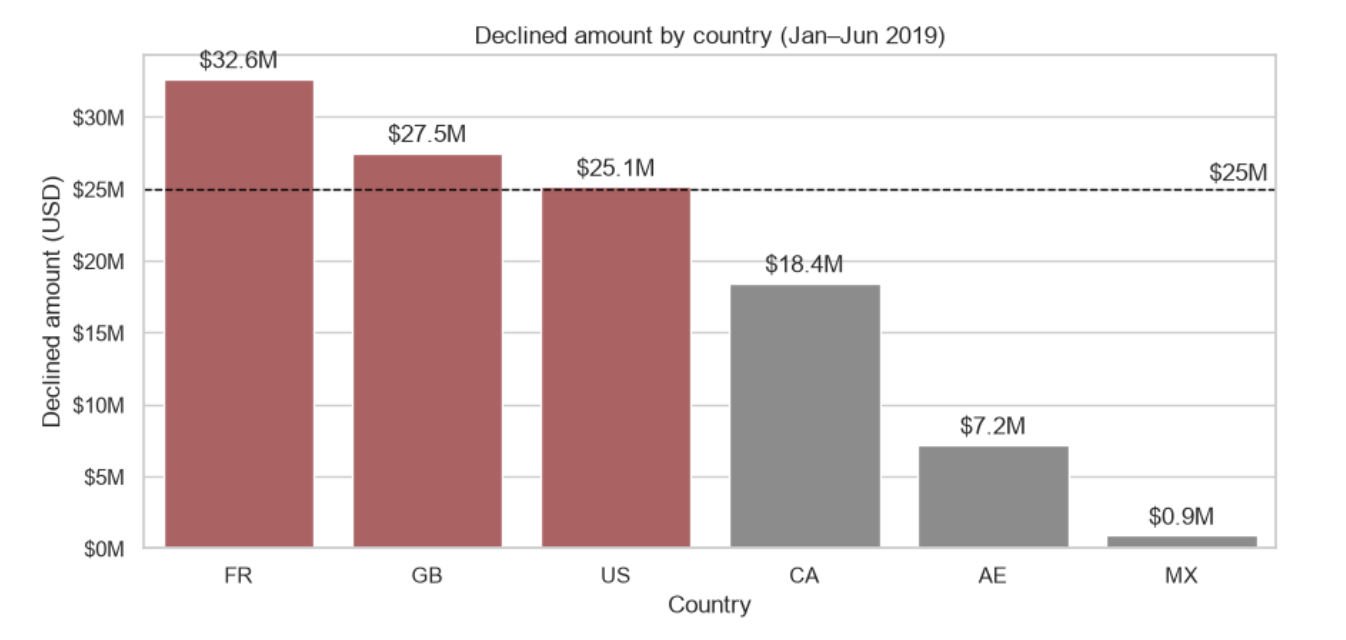

## 3. Which transactions are missing chargeback data?
All transactions have chargeback data

In [14]:
%%sql
SELECT
    *
FROM payments
WHERE has_chargeback_data IS FALSE
ORDER BY transacted_at


,external_ref,status,source,ref,transacted_at,transaction_date,state,is_accepted,is_cvv_provided,amount,country,currency,fx_rate_to_usd,amount_usd,is_chargeback,has_chargeback_data
